In [1]:
import pandas as pd

In [2]:
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
import plotly.colors as colors
pio.templates.default = "plotly_white"

In [3]:
data = pd.read_csv(r"X:\execl prictice\Sample_Superstore.csv", encoding="cp1252")
data.head(3)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11-08-2016,11-11-2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.0,41.9136
1,2,CA-2016-152156,11-08-2016,11-11-2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.0,219.5820
2,3,CA-2016-138688,06-12-2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.0,6.8714


In [4]:
data.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

# Converting date columns

In [6]:
data["Order Date"] = pd.to_datetime(data['Order Date'], format="mixed")
data["Ship Date"] = pd.to_datetime(data['Ship Date'], format="mixed")

In [7]:
data['Order Month']= data['Order Date'].dt.month
data['Order Year'] = data['Order Date'].dt.year
data['Order Day of week']= data['Order Date'].dt.dayofweek

#  Monthly sales analysis

In [8]:
sales_by_month = data.groupby("Order Month")["Sales"].sum().reset_index()

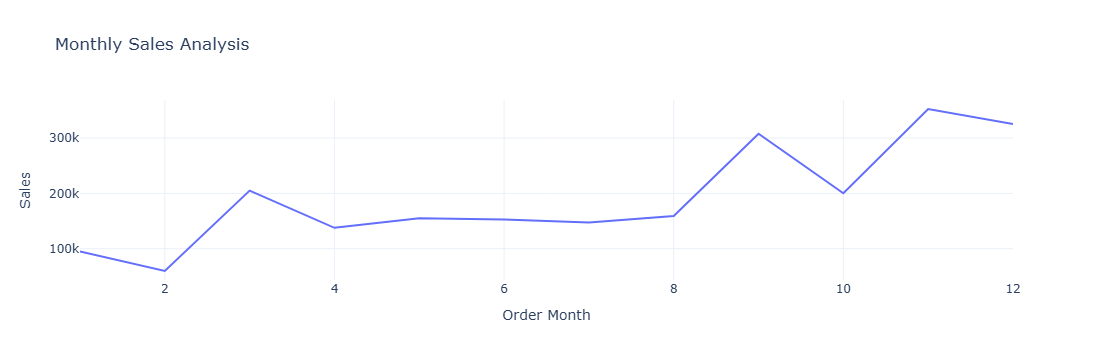

In [9]:
fig= px.line(sales_by_month, x='Order Month', y="Sales", title='Monthly Sales Analysis') 
fig.show()

# Sale By Category

In [23]:
Sales_by_category = data.groupby('Category')['Sales'].sum().reset_index()

In [24]:
Sale_by_category

,Category,Sales
0,Furniture,741999.7953
1,Office Supplies,719047.0320
2,Technology,836154.0330


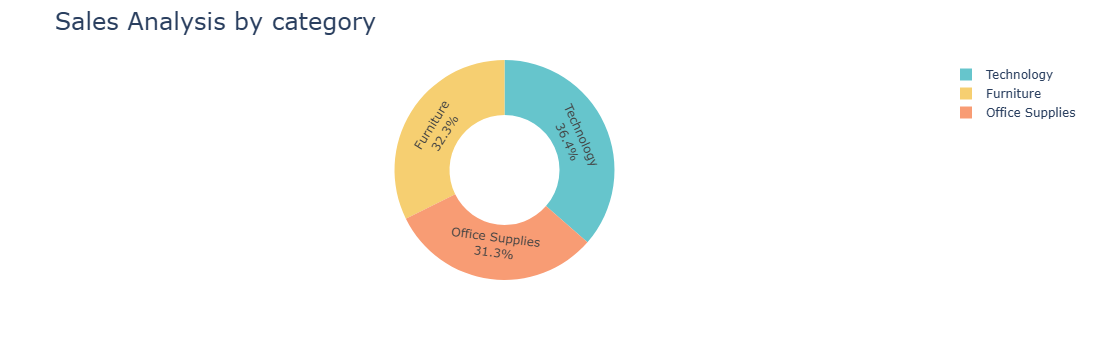

In [33]:
fig =px.pie(Sales_by_category, 
            values='Sales', 
            names='Category', 
            hole=0.5, 
            color_discrete_sequence =px.colors.qualitative.Pastel)
fig.update_traces(textposition='inside', textinfo='percent+label')
fig.update_layout(title_text='Sales Analysis by category', title_font=dict(size=24))   


fig.show()

# Sale Analysis By Subcatergory

sales_by_subcategory = data.groupby('Sub-Category')['Sales'].sum().reset_index()
sales_by_subcategory

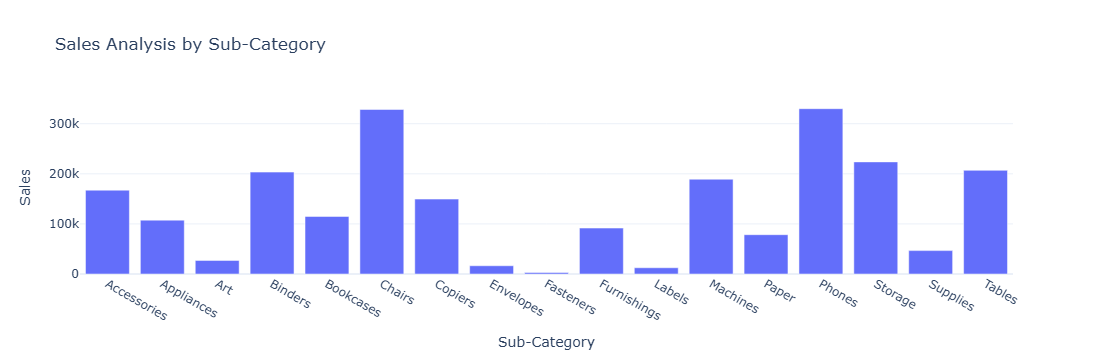

In [40]:
fig = px.bar(sales_by_subcategory, x='Sub-Category', y='Sales', title = 'Sales Analysis by Sub-Category')
fig.show()

# Monthly sale By Profit

In [44]:
monthly_sale_profit = data.groupby('Order Month')['Profit'].sum().reset_index()
# monthly_sale_profit

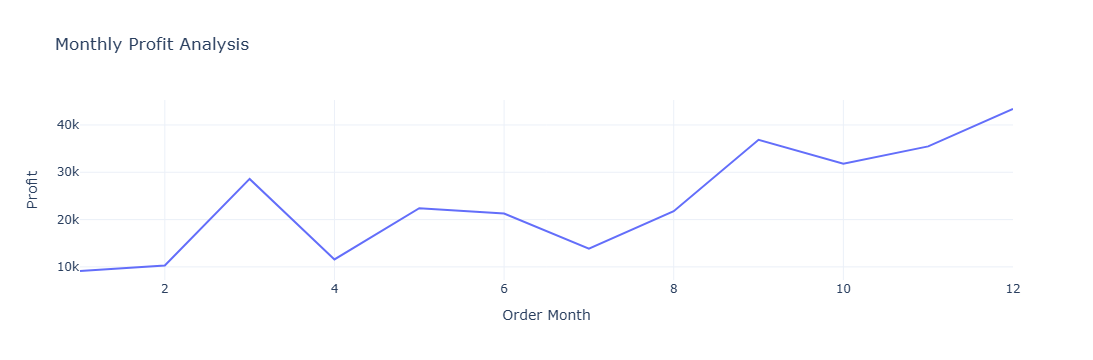

In [46]:
fig = px.line(monthly_sale_profit, x='Order Month',y='Profit' , title='Monthly Profit Analysis')
fig.show()

# Profit By Category

In [51]:
profit_by_category = data.groupby('Category')['Profit'].sum().reset_index()
# profit_by_category

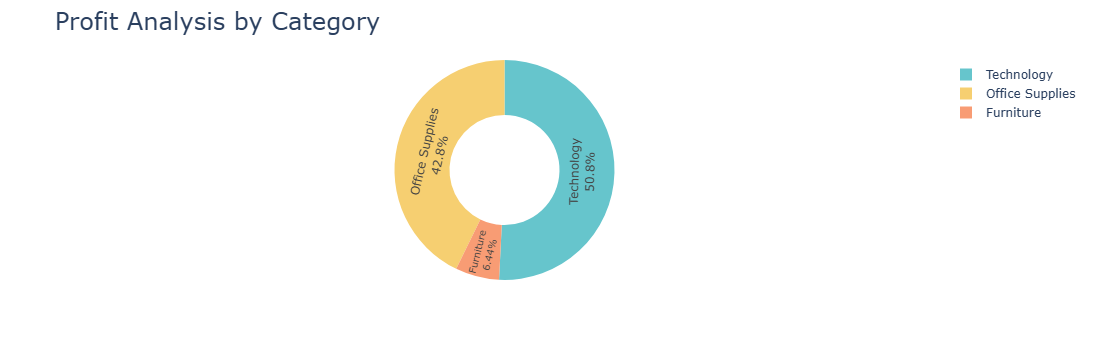

In [55]:
fig =px.pie(profit_by_category , 
            values='Profit', 
            names='Category', 
            hole=0.5, 
            color_discrete_sequence =px.colors.qualitative.Pastel)
fig.update_traces(textposition='inside', textinfo='percent+label')
fig.update_layout(title_text='Profit Analysis by Category', title_font=dict(size=24))   


fig.show()

# Profit By Sub-Category

In [56]:
profit_by_sub_category=data.groupby("Sub-Category")['Profit'].sum().reset_index()

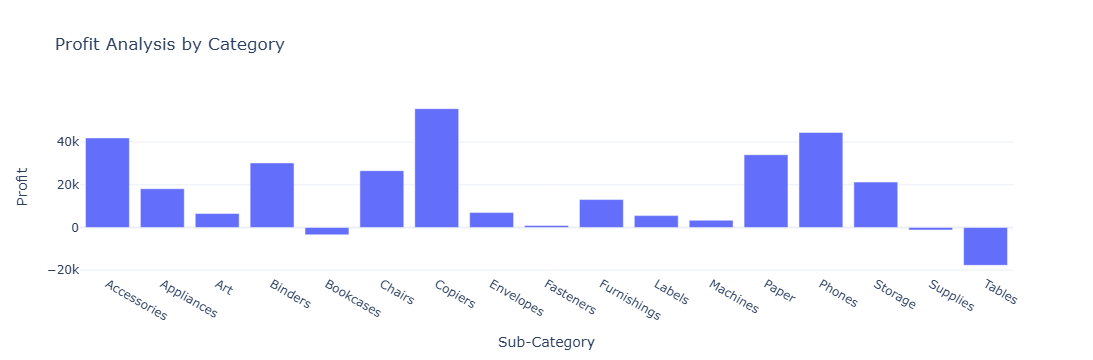

In [58]:
fig=px.bar(profit_by_sub_category, x='Sub-Category' , y='Profit',  title='Profit Analysis by Category')
fig.show()

# Sales And Profit - Customer

In [70]:
sales_profit_by_segment = data.groupby('Segment').agg({'Sales':'sum', 'Profit':'sum'}).reset_index()
# sales_profit_by_segment

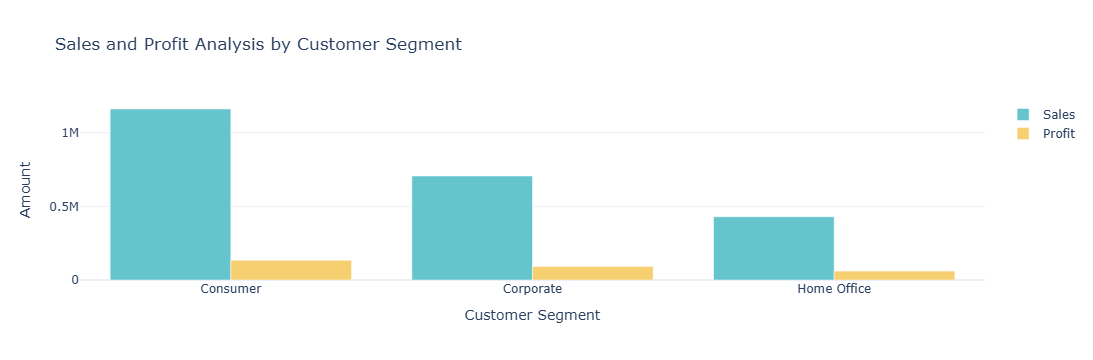

In [74]:
color_palette = colors.qualitative.Pastel

fig= go.Figure()
fig.add_trace(go.Bar(x=sales_profit_by_segment['Segment'],
                     y=sales_profit_by_segment['Sales'],
                     name='Sales',
                     marker_color=color_palette[0]))

fig.add_trace(go.Bar(x=sales_profit_by_segment['Segment'],
                     y=sales_profit_by_segment['Profit'],
                     name = 'Profit',
                    marker_color=color_palette[1]))
fig.update_layout(title='Sales and Profit Analysis by Customer Segment',
                 xaxis_title = 'Customer Segment', yaxis_title='Amount')

fig.show()


# Sales to Profit By Ratio

In [81]:
sales_profit_by_segment = data.groupby('Segment').agg({'Sales':'sum', 'Profit':'sum'}).reset_index()
sales_profit_by_segment['Sales_to_Profit_Ratio']=sales_profit_by_segment['Sales']/sales_profit_by_segment['Profit']

print(sales_profit_by_segment[['Segment', 'Sales_to_Profit_Ratio']])

       Segment  Sales_to_Profit_Ratio
0     Consumer               8.659471
1    Corporate               7.677245
2  Home Office               7.125416
